### THe Normal equation

In [1]:
# generate a linear data to test equation

In [2]:
import numpy as np
np.random.seed(42)

m= 100 # no of instances
X = 2*np.random.rand(m,1) # column vector 
y = 4+ 3*X + np.random.rand(m,1) # column vector

In [3]:
import matplotlib.pyplot as plt

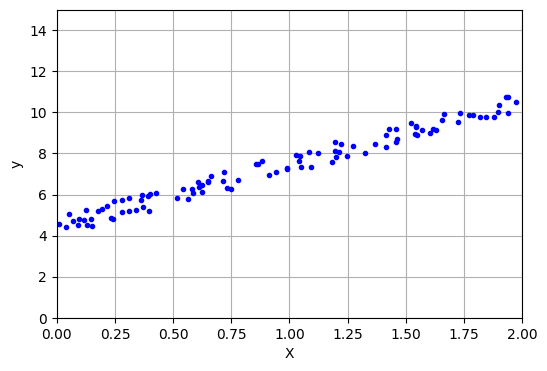

In [4]:
plt.figure(figsize=(6, 4))
plt.plot(X,y,"b.")
plt.axis([0,2,0,15]) # [xmin, xmax, ymin, ymax]
plt.xlabel("X")
plt.ylabel("y")
plt.grid()
plt.show()

In [5]:
# reaming pending

### gradient_decent

In [6]:
def batch_gradient_decent(X,y,epoch=1000,lr=0.01):
    m,n = X.shape
    # initialize weights
    w = np.ones(n)
    b = 0
    cost_list = []
    epoch_list = []
    for i in range(1,epoch+1):
        # forword pass
        y_pred = np.dot(X,w)+b
        # calculate error
        cost = (1/m)*np.sum((y-y_pred)**2) # MSE
        # calculate gradient
        dw = -(2/m)*np.dot(X.T,(y-y_pred))
        db = -(2/m)*np.sum((y-y_pred))
        # update gradient
        w = w-lr*dw
        b = b-lr*db
        if i%10==0:
            cost_list.append(cost)
            epoch_list.append(i)
            # print(f"Epoch: {i}, cost: {cost:.3f}")
    return w,b,cost,cost_list, epoch_list

In [7]:
def stochastic_gradient_descent(X,y_true,epochs=500, lr=0.01):
    # initialize weights
    m,n = X.shape
    w = np.ones(n,)
    b = 0
    cost_list = []
    epoch_list = []
    for i in range(1,epochs+1):
        #  forward pass
        sample = np.random.randint(0,m)
        y_pred = np.dot(X[sample],w)+b  
        # calculate error
        cost = (y_true[sample]-y_pred)**2 # MSE
        # calculate gradient
        dw = -2*(y_true[sample]-y_pred)*X[sample]
        db = -2*(y_true[sample]-y_pred)
        # update gradient
        w = w-lr*dw
        b = b-lr*db
        if i%10==0:
            cost_list.append(cost)
            epoch_list.append(i)
            # print(f"Epoch: {i}, cost: {cost:.3f}")
    return w,b,cost,cost_list, epoch_list

In [8]:
def mini_batch_gradient_descent(X,y_true,epochs=100,lr=0.01,batch_size = 5):
    m,n = X.shape
    # initialize weights
    w = np.ones(n)
    b = 0
    if batch_size>m: # In this case mini batch becomes same as batch gradient descent
        batch_size = m
    num_batches = m//batch_size
    cost_list = []
    epoch_list = []
    # no of epochs
    for i in range(epochs):
        random_idx = np.random.permutation(m)
        temp_X = X[random_idx]
        temp_y = y_true[random_idx]
        # lopps for batchs. [1,3,6,2,4,5],2 batchs with size 3: 1st batch [1,3,6], 2nd batch [2,4,5]
        for j in range(0,m,batch_size):
            # batch samples
            Xj = temp_X[j:j+batch_size]
            yj = temp_y[j:j+batch_size]
            # forward pass
            y_pred = np.dot(Xj,w)+b
            # calculate loss
            cost = np.mean(np.square(yj-y_pred)) # (1/batch_size)*np.sum((yj-y_pred)**2) #MSE
            # claculate gradient
            dw = -(2/len(Xj))*np.dot(Xj.T,(yj-y_pred))
            db = -(2/len(Xj))*np.sum(yj-y_pred)
            # update weights
            w = w - lr * dw
            b = b- lr*db
        if i%10==0:
            cost_list.append(cost)
            epoch_list.append(i)
            # print(f"Epoch: {i}, cost: {cost:.3f}")
    return w,b,cost,cost_list, epoch_list
            

### polynomial features

In [9]:
# data
np.random.seed(42)
m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X ** 2 + X + 2 + np.random.randn(m, 1)

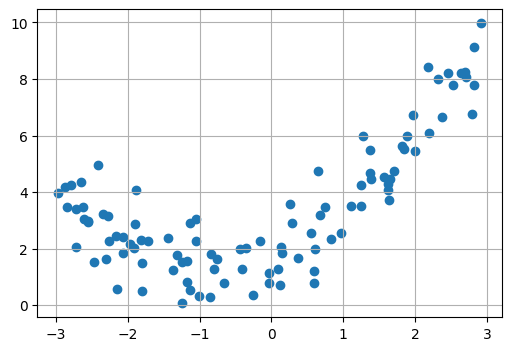

In [10]:
plt.figure(figsize=(6, 4))
plt.scatter(X,y)
plt.grid()
plt.show()

In [11]:
X[0]

array([-0.75275929])

In [12]:
from sklearn.preprocessing import PolynomialFeatures

In [13]:
poly_features = PolynomialFeatures(degree=2,include_bias=False)
X_poly = poly_features.fit_transform(X)

In [14]:
X_poly[0]

array([-0.75275929,  0.56664654])

In [15]:
from sklearn.linear_model import LinearRegression

In [16]:
model = LinearRegression()
model.fit(X_poly,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [17]:
model.coef_,model.intercept_

(array([[0.93366893, 0.56456263]]), array([1.78134581]))

In [18]:
model.predict([X_poly[0]])

array([[1.39842532]])

In [19]:
y[0]

array([1.61761105])

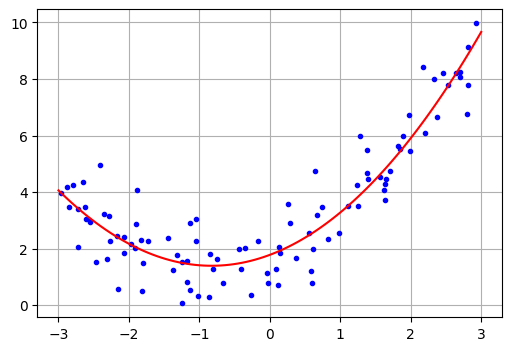

In [20]:
X_new = np.linspace(-3,3,100).reshape(-1,1)
X_new_poly = poly_features.transform(X_new)
y_pred = model.predict(X_new_poly)

plt.figure(figsize=(6, 4))
plt.plot(X,y,'b.')
plt.plot(X_new,y_pred,'r-')
plt.grid()
plt.show()

### Learning curves

In [21]:
from sklearn.model_selection import learning_curve

Use Linear Regression

Dataset = (X, y)

Train on 40 different dataset sizes. from 1% → 100% of data

Use 5-fold cross-validation

Metric = RMSE
(negative because scikit-learn expects higher is better)

In [22]:
np.linspace(0.01,1,40)

array([0.01      , 0.03538462, 0.06076923, 0.08615385, 0.11153846,
       0.13692308, 0.16230769, 0.18769231, 0.21307692, 0.23846154,
       0.26384615, 0.28923077, 0.31461538, 0.34      , 0.36538462,
       0.39076923, 0.41615385, 0.44153846, 0.46692308, 0.49230769,
       0.51769231, 0.54307692, 0.56846154, 0.59384615, 0.61923077,
       0.64461538, 0.67      , 0.69538462, 0.72076923, 0.74615385,
       0.77153846, 0.79692308, 0.82230769, 0.84769231, 0.87307692,
       0.89846154, 0.92384615, 0.94923077, 0.97461538, 1.        ])

In [23]:
train_sizes, train_sores, val_scores = learning_curve(
    LinearRegression(),
    X,
    y,
    train_sizes=np.linspace(0.01,1,40),
    cv=5,
    scoring='neg_root_mean_squared_error'
)

In [24]:
train_sizes, train_sizes.shape

(array([ 1,  2,  4,  6,  8, 10, 12, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33,
        35, 37, 39, 41, 43, 45, 47, 49, 51, 53, 55, 57, 59, 61, 63, 65, 67,
        69, 71, 73, 75, 77, 80]),
 (40,))

In [25]:
train_sores[:5]

array([[-0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
        -0.00000000e+00, -0.00000000e+00],
       [-4.44089210e-16, -3.14018492e-16, -3.14018492e-16,
        -3.14018492e-16, -3.14018492e-16],
       [-6.74202452e-01, -1.35541971e+00, -1.35541971e+00,
        -1.35541971e+00, -1.35541971e+00],
       [-1.12165340e+00, -1.66264469e+00, -1.66264469e+00,
        -1.66264469e+00, -1.66264469e+00],
       [-1.06106104e+00, -1.82896912e+00, -1.82896912e+00,
        -1.82896912e+00, -1.82896912e+00]])

In [26]:
train_sores.shape  # 40 training sizes, 5 CV folds per size,Each value = training score

(40, 5)

In [27]:
val_scores.shape

(40, 5)

In [28]:
# convert scores to eroor
'''
Scores were negative RMSE
We want positive error
Take mean across folds
Now you have:
One training error per data size
One validation error per data size
'''
train_errors = - np.mean(train_sores,axis=1)
val_errors = - np.mean(val_scores,axis=1)

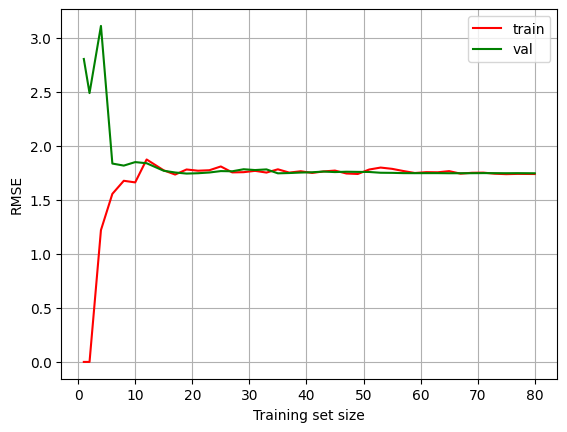

In [29]:
plt.plot(train_sizes,train_errors,'r-',label="train")
plt.plot(train_sizes,val_errors,'g-',label='val')
plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.legend()
plt.grid()
plt.show()

In [30]:
# learning curves for polynomial regression

In [31]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [32]:
polynomial_regression = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

In [33]:
train_sizes, train_sores, val_scores = learning_curve(
    polynomial_regression,
    X,
    y,
    train_sizes=np.linspace(0.01,1,40),
    cv=5,
    scoring='neg_root_mean_squared_error'
)

In [34]:
train_errors = - train_sores.mean(axis=1)
val_errors = - val_scores.mean(axis=1)

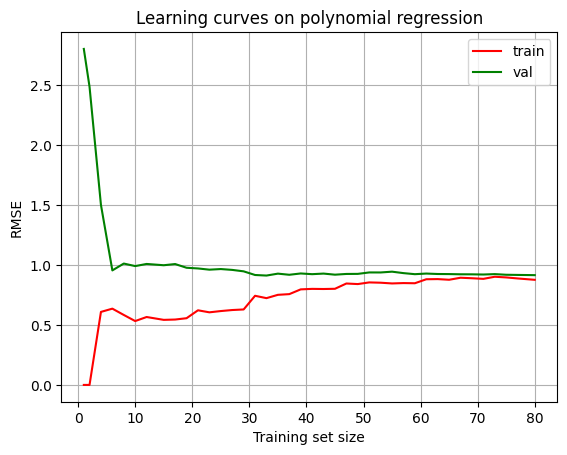

In [35]:
plt.plot(train_sizes,train_errors,'r-',label="train")
plt.plot(train_sizes,val_errors,'g-',label='val')
plt.title("Learning curves on polynomial regression")
plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.legend()
plt.grid()
plt.show()

## Regularized Linear Models

### Ridge Regression

In [36]:
from sklearn.linear_model import Ridge

In [37]:
polynomial_regression = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=5, include_bias=False),
    Ridge(alpha=0.1)
)

In [38]:
np.random.seed(42)
m = 20
X = 3 * np.random.rand(m, 1)
y = 1 + 0.5 * X + np.random.randn(m, 1) / 1.5
X_new = np.linspace(0, 3, 100).reshape(100, 1)

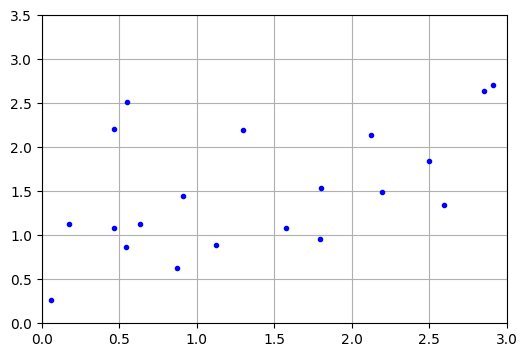

In [39]:
plt.figure(figsize=(6, 4))
plt.plot(X,y,'b.')
plt.axis([0, 3, 0, 3.5])
plt.grid()
plt.show()

In [40]:
polynomial_regression_normal = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=10, include_bias=False),
    LinearRegression()
)

In [41]:
polynomial_regression_normal.fit(X,y)

,steps,"[('standardscaler', ...), ('polynomialfeatures', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,10
,interaction_only,False
,include_bias,False
,order,'C'


In [42]:
polynomial_regression_ridge = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=10, include_bias=False),
    Ridge(alpha=5.0)
)

In [43]:
polynomial_regression_ridge.fit(X,y)

,steps,"[('standardscaler', ...), ('polynomialfeatures', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,10
,interaction_only,False
,include_bias,False
,order,'C'


In [44]:
polynomial_regression_ridge.score(X,y)

0.49545233679388057

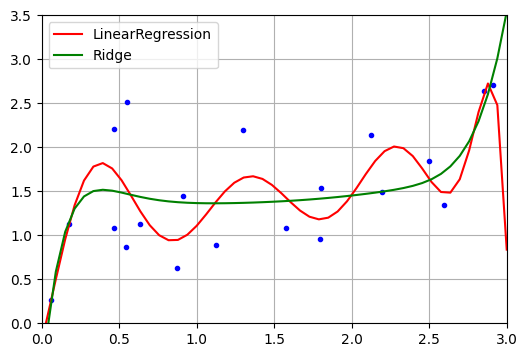

In [45]:
X_new = np.linspace(-3,3,100).reshape(-1,1)
y_pred_1 = polynomial_regression_normal.predict(X_new)
y_pred_2 = polynomial_regression_ridge.predict(X_new)

plt.figure(figsize=(6, 4))
plt.plot(X,y,'b.')
plt.plot(X_new,y_pred_1,'r-',label="LinearRegression")
plt.plot(X_new,y_pred_2,'g-',label="Ridge")
plt.axis([0, 3, 0, 3.5])
plt.legend()
plt.grid()
plt.show()

Ridge Regression can be solved in two different ways:

Closed-form (direct math solution)

Gradient descent (iterative optimization)

In [46]:
# Ridge closed-form
ridge_reg = Ridge(alpha=0.1,solver="cholesky")  # solver="cholesky": Solve the Ridge normal equation efficiently
ridge_reg.fit(X,y)
ridge_reg.predict([[1.5]])

array([1.55325833])

In [47]:
# Now the second way: Gradient Descent, Loss=MSE+α∑wj^2
from sklearn.linear_model import SGDRegressor

In [48]:
sgd_reg = SGDRegressor(
    penalty='l2',
    alpha=0.1/m,
    tol=None,
    max_iter=1000, 
    eta0=0.01, 
    random_state=42
)
# we use /m in alpha=0.1/m because SGD does not divide MSE by m, Ridge does, So to make them equivalent.it’s just matching the math.

In [49]:
sgd_reg.fit(X,y.ravel())# y.ravel() because fit() expects 1D targets
sgd_reg.predict([[1.5]])

array([1.55302613])

In [50]:
# show that we get roughly the same solution as earlier when
# we use Stochastic Average GD (solver="sag")
ridge_reg = Ridge(alpha=0.1,solver="sag",random_state=42)
ridge_reg.fit(X,y)
ridge_reg.predict([[1.5]])

array([1.55326019])

In [51]:
from sklearn.linear_model import RidgeCV

In [52]:
ridge_cv = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=10,include_bias=False),
    RidgeCV(alphas=(0.1, 1.0,5.0, 10.0))
)

In [53]:
ridge_cv.fit(X,y)

,steps,"[('standardscaler', ...), ('polynomialfeatures', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,10
,interaction_only,False
,include_bias,False
,order,'C'


In [54]:
ridge_cv.score(X,y)

0.4860690533551867

In [55]:
ridge_cv.named_steps['ridgecv'].alpha_

np.float64(10.0)

In [56]:
# so, 10 is the best between (0.1, 1.0,5.0, 10.0)

### Lasso Regression 

In [57]:
from sklearn.linear_model import Lasso

In [58]:
lasso = Lasso(alpha=0.1)
lasso.fit(X,y)
lasso.predict([[1.5]])

array([1.53788174])

In [59]:
polynomial_regression_lasso = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=10, include_bias=False),
    Lasso(alpha=5.0)
)

In [60]:
polynomial_regression_lasso.fit(X,y)

,steps,"[('standardscaler', ...), ('polynomialfeatures', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,10
,interaction_only,False
,include_bias,False
,order,'C'


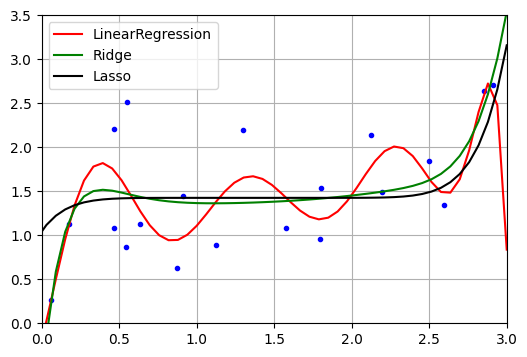

In [61]:
X_new = np.linspace(-3,3,100).reshape(-1,1)
y_pred_1 = polynomial_regression_normal.predict(X_new)
y_pred_2 = polynomial_regression_ridge.predict(X_new)
y_pred_3 = polynomial_regression_lasso.predict(X_new)
plt.figure(figsize=(6, 4))
plt.plot(X,y,'b.')
plt.plot(X_new,y_pred_1,'r-',label="LinearRegression")
plt.plot(X_new,y_pred_2,'g-',label="Ridge")
plt.plot(X_new,y_pred_3,'black',label="Lasso")
plt.axis([0, 3, 0, 3.5])
plt.legend()
plt.grid()
plt.show()

In [62]:
from sklearn.linear_model import LassoCV

In [63]:
lasso_cv = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=10, include_bias=False),
    LassoCV(alphas=[0.01, 0.1, 1,5, 10],max_iter=10000) # max_iter=5000: Lasso optimization is harder, Needs more iterations to converge
)

In [64]:
lasso_cv.fit(X,y.ravel())

/home/sureshsecond/venv/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.874e-02, tolerance: 7.333e-04
  model = cd_fast.enet_coordinate_descent_gram(
/home/sureshsecond/venv/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.392e-03, tolerance: 8.452e-04
  model = cd_fast.enet_coordinate_descent_gram(
/home/sureshsecond/venv/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regulari

,steps,"[('standardscaler', ...), ('polynomialfeatures', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,10
,interaction_only,False
,include_bias,False
,order,'C'


In [65]:
lasso_cv.score(X,y)

0.4625212009384204

In [66]:
lasso_cv.named_steps

{'standardscaler': StandardScaler(),
 'polynomialfeatures': PolynomialFeatures(degree=10, include_bias=False),
 'lassocv': LassoCV(alphas=[0.01, 0.1, 1, 5, 10], max_iter=10000)}

In [67]:
best = lasso_cv.named_steps["lassocv"].alpha_
best

np.float64(0.1)

### Elastic Net Regression

In [68]:
from sklearn.linear_model import ElasticNet

In [69]:
elasticnet = ElasticNet(alpha=0.1,l1_ratio=0.5)
elasticnet.fit(X,y)
elasticnet.predict([[1.5]])

array([1.54333232])

In [70]:
polynomial_regression_elastic = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=10, include_bias=False),
    ElasticNet(alpha=5.0,l1_ratio=0.5)
)

In [71]:
polynomial_regression_elastic.fit(X,y)

,steps,"[('standardscaler', ...), ('polynomialfeatures', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,10
,interaction_only,False
,include_bias,False
,order,'C'


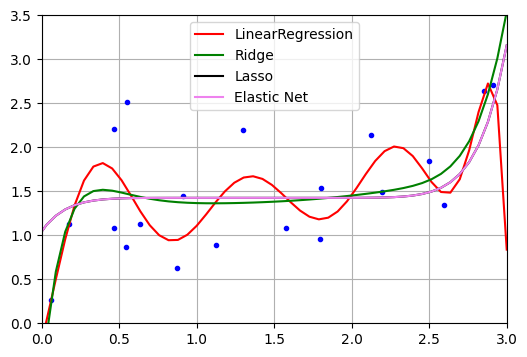

In [72]:
X_new = np.linspace(-3,3,100).reshape(-1,1)
y_pred_1 = polynomial_regression_normal.predict(X_new)
y_pred_2 = polynomial_regression_ridge.predict(X_new)
y_pred_3 = polynomial_regression_lasso.predict(X_new)
y_pred_4 = polynomial_regression_elastic.predict(X_new)
plt.figure(figsize=(6, 4))
plt.plot(X,y,'b.')
plt.plot(X_new,y_pred_1,'r-',label="LinearRegression")
plt.plot(X_new,y_pred_2,'g-',label="Ridge")
plt.plot(X_new,y_pred_3,'black',label="Lasso")
plt.plot(X_new,y_pred_3,'violet',label="Elastic Net")
plt.axis([0, 3, 0, 3.5])
plt.legend()
plt.grid()
plt.show()

In [73]:
from sklearn.linear_model import ElasticNetCV

In [74]:
elastic_netcv = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=10, include_bias=False),
    ElasticNetCV(alphas=[ 0.1, 1, 10],
        l1_ratio=[0.5, 0.9,5],
        cv=5)
)
# or just regr = ElasticNetCV(cv=5, random_state=0), regr.alpha_

In [75]:
elastic_netcv.fit(X,y.ravel())

,steps,"[('standardscaler', ...), ('polynomialfeatures', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,10
,interaction_only,False
,include_bias,False
,order,'C'


In [76]:
elastic_netcv.named_steps['elasticnetcv'].alpha_,elastic_netcv.named_steps['elasticnetcv'].l1_ratio_

(np.float64(0.1), np.float64(0.9))

### Early stopping

In [77]:
from copy import deepcopy
from sklearn.metrics import root_mean_squared_error

In [78]:
np.random.seed(42)
m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X ** 2 + X + 2 + np.random.randn(m, 1)
X_train, y_train = X[: m // 2], y[: m // 2, 0]
X_valid, y_valid = X[m // 2 :], y[m // 2 :, 0]

In [79]:
X.shape

(100, 1)

In [80]:
X_train.shape,X_valid.shape

((50, 1), (50, 1))

In [81]:
# preprocessing
preprocess = make_pipeline(
    PolynomialFeatures(degree=90,include_bias=False),
    StandardScaler()
)

In [82]:
X_train_pre = preprocess.fit_transform(X_train)
X_valid_pre = preprocess.transform(X_valid)

In [83]:
# model
sgd_reg = SGDRegressor(penalty=None, eta0=0.002,random_state=42)
# penality none means no l1 or L2

In [84]:
epochs = 500
best_valid_rmse = float('inf')
train_errors, val_errors = [],[]
for i in range(epochs):
    sgd_reg.partial_fit(X_train_pre,y_train)
    y_val_pred = sgd_reg.predict(X_valid_pre)
    val_error = root_mean_squared_error(y_valid,y_val_pred)
    if val_error<best_valid_rmse:
        best_valid_rmse = val_error
        best_model = deepcopy(sgd_reg)
    y_train_pred = sgd_reg.predict(X_train_pre)
    train_error = root_mean_squared_error(y_train,y_train_pred)
    train_errors.append(train_error)
    val_errors.append(val_error)

In [85]:
best_epoch = np.argmin(val_errors)

In [86]:
len(val_errors)

500

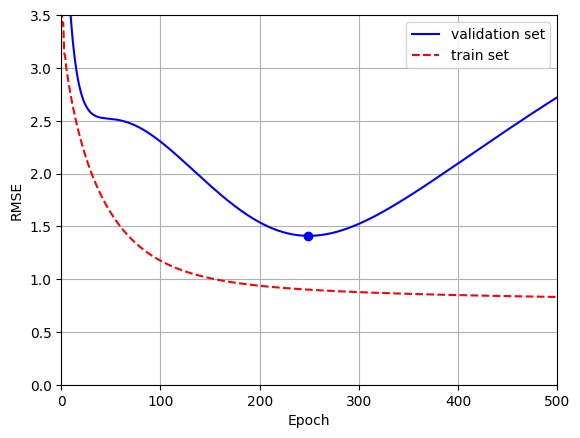

In [87]:
plt.plot(val_errors,"b",label="validation set") # # plot y using x as index array 0..N-1
plt.plot(train_errors,"r--",label='train set')
plt.plot(best_epoch,best_valid_rmse,"bo")
plt.axis([0, epochs, 0, 3.5])
plt.grid()
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()
plt.show()

#### patience-based early stopping

In [88]:
sgd_reg = SGDRegressor(penalty=None, eta0=0.002,random_state=42)

In [89]:
epochs=500
best_rmse = np.inf
best_model=None
patience = 10
wait =0
for epoch in range(epochs):
    sgd_reg.partial_fit(X_train_pre,y_train)
    y_val_pred = sgd_reg.predict(X_valid_pre)
    val_rmse = root_mean_squared_error(y_valid,y_val_pred)
    if val_rmse<best_rmse:
        best_rmse = val_rmse
        best_model = deepcopy(sgd_reg)
        wait=0  # reset
    else:
        wait+=1
    if wait>=patience:
        print(f"Early stopping at epoch {epoch}")
        break

Early stopping at epoch 259


In [90]:
model = best_model

In [91]:
model.intercept_

array([3.0874158])

### Logistic Regression

Let’s try to build a classifier to detect the Iris virginica type based only on the
petal width feature.

In [92]:
from sklearn.datasets import load_iris

In [93]:
iris = load_iris(as_frame=True)

In [94]:
list(iris)

['data',
 'target',
 'frame',
 'target_names',
 'DESCR',
 'feature_names',
 'filename',
 'data_module']

In [96]:
iris.data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [97]:
iris.target.head()

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [101]:
# note that instanses are not suffled

In [98]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [99]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [132]:
X = iris.data[["petal width (cm)"]].values
y = np.array([iris.target==2]).reshape(-1,) # True if virginica else False

In [121]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [133]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

In [134]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [137]:
log_reg.intercept_

array([-6.32263658])

In [142]:
log_reg.predict([[1.7], [1.5]])

array([ True, False])

predict_proba() returns For binary classification, shape is:(1000, 2)Each row:[P(not virginica), P(virginica)]

In [146]:
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)  # reshape to get a column vector
y_proba = log_reg.predict_proba(X_new)
y_proba

array([[0.99820801, 0.00179199],
       [0.99818732, 0.00181268],
       [0.99816638, 0.00183362],
       ...,
       [0.00578965, 0.99421035],
       [0.00572381, 0.99427619],
       [0.00565872, 0.99434128]], shape=(1000, 2))

### Softmax regression

In [138]:
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target

In [139]:
X.shape,y.shape

((150, 2), (150,))

In [140]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

Scikit-Learn’s LogisticRegression classifier uses softmax regression
automatically when you train it on more than two classes (assuming you use
solver="lbfgs", which is the default). It also applies ℓ2 regularization bydefault, which you can control using the hyperparameter C

In [141]:
softmax_reg = LogisticRegression(C=10,random_state=42)
softmax_reg.fit(X,y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,10
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [143]:
softmax_reg.predict([[5, 2]])

array([2])

In [145]:
softmax_reg.predict_proba([[5, 2]]).round(2)

array([[0.  , 0.06, 0.94]])